#### Breathing and tremor disturbance: signal and PD baseline 

A toy simulation of a needle tip tracking a target that moves with slow breathing plus fast tremor, measured through a noisy sensor. This project builds the signal, looks at its spectrum, and sets a non-learning PD baseline for later comparison with a Kalman-based compensator.

#### 1. Simulated signal: Position over time 

Target position (mm) is the sum of three parts:
- breathing: 15mm amplitude at 0.25 Hz (slow, large)
- tremor: 0.5 mm amplitude at 10 HZ (fast, small)
- Sensor noise: random jitters on the measurement 

Sampled at 1000 Hz for 60 seconds. On the full plot the tremor is hidden inside the line width.

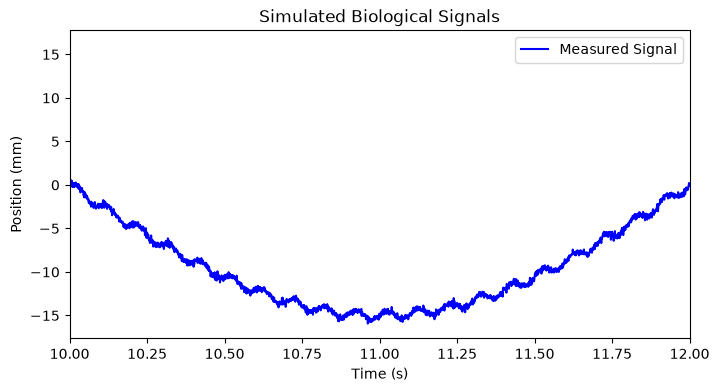

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000  # Sampling frequency, samples per second
duration = 60 # Duration of the signal in seconds
t = np.arange(0, duration, 1/fs)  # Time axis

breathing_rate = 15 * np.sin(2 * np.pi * 0.25 * t)  # Simulated breathing rate signal (15 breaths per minute)
tremor = 0.5 * np.sin(2 * np.pi * 10 * t)  # Simulated tremor signal (1 Hz)

rng = np.random.default_rng(0)  # Random number generator for reproducibility
noise = rng.normal(0, 0.2, size=t.shape)  # sensor noise

measured = breathing_rate + tremor + noise  # Combined signal

plt.figure(figsize=(8, 4))
plt.plot(t, measured, label='Measured Signal', color='blue')
plt.xlabel('Time (s)')
plt.ylabel('Position (mm)')
plt.title('Simulated Biological Signals')
plt.legend()
plt.show()

### 2. Frequenxy spectrum (FFT)

The FFT shows whichfrequencues are precent and how strong each is. Expected and observed:
- Spike at 0.23 Hz, about 15mm: breathing 
- SPike at 10 Hz, about 0.5mm: tremor 
- A low flat floor: sensor noise spread across all frequenceies

A log scale is used beacuse the tremor spike is tiny next to the breathing spike.

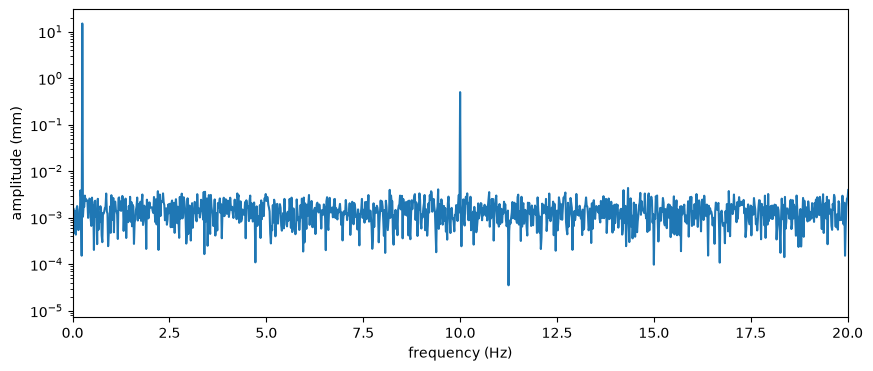

In [6]:
spectrum = np.fft.rfft(measured)
freqs = np.fft.rfftfreq(len(measured), d=1/fs)
amplitude = np.abs(spectrum) * 2 / len(measured)

plt.figure(figsize=(10, 4))
plt.plot(freqs, amplitude)
plt.xlim(0, 20)
plt.yscale("log")
plt.xlabel("frequency (Hz)")
plt.ylabel("amplitude (mm)")
plt.show()

## 3. PD baseline controller
The needle tip is modelled as a simple mass: the controller output set its acceleration. It sees the noisy measurement and tries to follow it.
- P term: pulls the tip toward the target 
- D term: brakes using the tip's own velocity (avoids differatiating noise)

Metric: RMSE between the true (noise-free) target and tip position. A do-nothing tip (held at 0) gives 10.61mm

PD tracking RMSE: 1.68 mm
Do-nothing RMSE:  10.61 mm


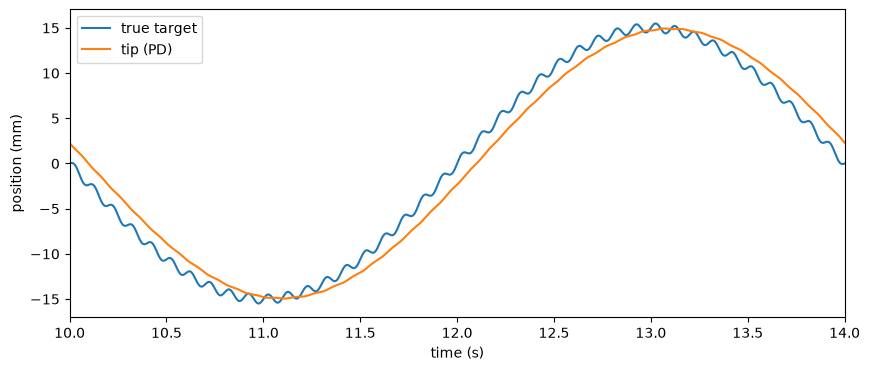

In [8]:
breathing = 15 * np.sin(2 * np.pi * 0.25 * t)
tremor = 0.5 * np.sin(2 * np.pi * 10 * t)

kp, kd = 400.0, 40.0  # kp: how hard it pulls toward the target, kd: brake on tip speed
dt = 1/fs

true_target = breathing + tremor # what the tip SHOULD follow (no noise)
y = 0.0                  # tip position (mm)
v = 0.0                  # tip velocity (mm/s)
tip = np.zeros_like(t)

for i in range(len(t)):
    e = measured[i] - y          # error, using the noisy sensor reading
    u = kp * e - kd * v          # PD control signal
    v += u * dt
    y += v * dt
    tip[i] = y

error = true_target - tip
rmse = np.sqrt(np.mean(error**2))
print(f"PD tracking RMSE: {rmse:.2f} mm")
print(f"Do-nothing RMSE:  {np.sqrt(np.mean(true_target**2)):.2f} mm")

plt.figure(figsize=(10, 4))
plt.plot(t, true_target, label="true target")
plt.plot(t, tip, label="tip (PD)")
plt.xlim(10, 14)
plt.xlabel("time (s)")
plt.ylabel("position (mm)")
plt.legend()
plt.show()

PD tracking RMSE: 0.76 mm
Do-nothing RMSE:  10.61 mm


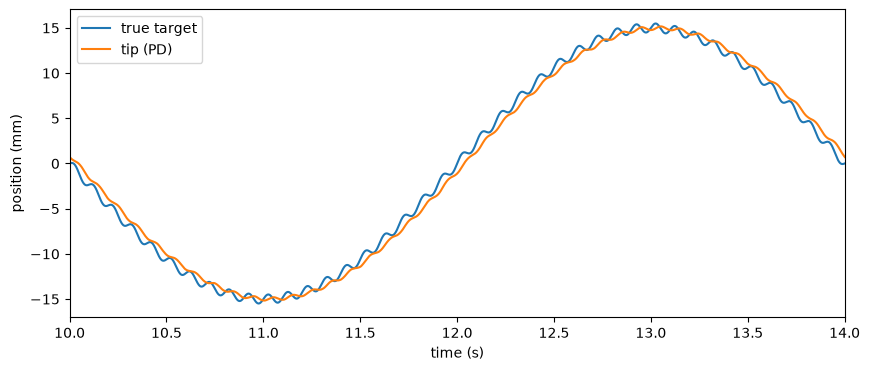

In [9]:
breathing = 15 * np.sin(2 * np.pi * 0.25 * t)
tremor = 0.5 * np.sin(2 * np.pi * 10 * t)

kp, kd = 2500.0, 100.0  # kp: how hard it pulls toward the target, kd: brake on tip speed
dt = 1/fs

true_target = breathing + tremor # what the tip SHOULD follow (no noise)
y = 0.0                  # tip position (mm)
v = 0.0                  # tip velocity (mm/s)
tip = np.zeros_like(t)

for i in range(len(t)):
    e = measured[i] - y          # error, using the noisy sensor reading
    u = kp * e - kd * v          # PD control signal
    v += u * dt
    y += v * dt
    tip[i] = y

error = true_target - tip
rmse = np.sqrt(np.mean(error**2))
print(f"PD tracking RMSE: {rmse:.2f} mm")
print(f"Do-nothing RMSE:  {np.sqrt(np.mean(true_target**2)):.2f} mm")

plt.figure(figsize=(10, 4))
plt.plot(t, true_target, label="true target")
plt.plot(t, tip, label="tip (PD)")
plt.xlim(10, 14)
plt.xlabel("time (s)")
plt.ylabel("position (mm)")
plt.legend()
plt.show()

### Effect of gain (no delay)

| kp | kd | RMSE |
|---|---|---|
| 400 | 40 | 1.68 mm |
| 2500 | 100 | 0.76 mm |

Higher gain reduces the lag on breathing and tracks part of the tremor. In this idealised setup there is no latency, so gain keeps helping.

## 4. Effect of sensing delay

The target reading is delayed by 50 ms (the tip's own feedback is not delayed, a simplification).

| kp | RMSE, 0 ms delay | RMSE, 50 ms delay |
|---|---|---|
| 100 | 3.25 mm | 4.05 mm |
| 400 | 1.68 mm | 2.48 mm |
| 1000 | 1.11 mm | 1.89 mm |
| 2500 | 0.76 mm | 1.52 mm |
| 5000 | 0.58 mm | 1.36 mm |

With delay, raising the gain no longer closes the gap.


In [14]:
def run_pd(kp, kd, delay_steps=0):
    y, v = 0.0, 0.0
    tip = np.zeros_like(t)
    for i in range(len(t)):
        j = max(i - delay_steps, 0)      # target reading is delay_steps samples old
        e = measured[j] - y
        u = kp * e - kd * v
        v += u * dt
        y += v * dt
        tip[i] = y
    return tip

def rmse_of(tip):
    return np.sqrt(np.mean((true_target - tip) ** 2))

for delay_ms in [0, 50]:
    n = round(delay_ms / 1000 * fs)
    for kp in [100, 400, 1000, 2500, 5000]:
        kd = 2 * np.sqrt(kp)             # keeps the response critically damped
        print(f"delay {delay_ms} ms, kp {kp:>5}, kd {kd:5.1f}: RMSE {rmse_of(run_pd(kp, kd, n)):.2f} mm")



delay 0 ms, kp   100, kd  20.0: RMSE 3.25 mm
delay 0 ms, kp   400, kd  40.0: RMSE 1.68 mm
delay 0 ms, kp  1000, kd  63.2: RMSE 1.11 mm
delay 0 ms, kp  2500, kd 100.0: RMSE 0.76 mm
delay 0 ms, kp  5000, kd 141.4: RMSE 0.58 mm
delay 50 ms, kp   100, kd  20.0: RMSE 4.05 mm
delay 50 ms, kp   400, kd  40.0: RMSE 2.48 mm
delay 50 ms, kp  1000, kd  63.2: RMSE 1.89 mm
delay 50 ms, kp  2500, kd 100.0: RMSE 1.52 mm
delay 50 ms, kp  5000, kd 141.4: RMSE 1.36 mm


### Staleness floor

If a controller tracks a 50 ms old reading perfectly, it is still wrong by how much the target moved in those 50 ms. This gives a lower bound for any purely reactive controller:

**1.09 mm at 50 ms delay.**

Only prediction (estimating where the target is now) can go below this. This is the number the Kalman-based compensator would need to beat 


In [15]:
print("fs =", fs)
n = round(0.050 * fs)        # 50 ms in samples, whatever fs is
floor = np.sqrt(np.mean((true_target[n:] - true_target[:-n]) ** 2))
print(f"n = {n} samples, staleness floor at 50 ms: {floor:.2f} mm")

fs = 1000
n = 50 samples, staleness floor at 50 ms: 1.09 mm


## Limitations

- Breathing and tremor are idealised sine waves, not real physiological recordings.
- The plant is a toy mass model, not a real robot.
- Delay is applied only to the target reading, not to the tip feedback.
- Amplitudes, frequencies and noise level are placeholders, to be refined from the literature.